# Reading and Plotting DASHub Data

Qiushi Zhai, Caltech

May 26, 2026

This notebook provides example functions and scripts for reading and visualizing DAS data stored in the DASHub format. We use the **Ridgecrest_South** dataset as a working example.

The data is organized on the server with the following top-level structure:

```
$ pwd
/DASdata/Ridgecrest_South
$ ls
CFR  DS  Events  Info  LF  ZFP
```

Channel location information is stored in the `Info` directory, and cut seismic event waveforms are stored in the `Events` directory. The remaining directories contain continuous recording data in different versions, described below.

- **`CFR`** — Continuous Full Resolution. (e.g., Ridgecrest_South: 10 m channel spacing, 100 Hz sample rate, low-pass filtered at 40 Hz)
- **`ZFP`** — ZFP-lossy-compressed; only temporally downsampled, then compressed with the ZFP library (max error tolerance: 20×10⁻³). (e.g., Ridgecrest_South: 10 m channel spacing, 50 Hz sample rate, low-pass filtered at 20 Hz)
- **`DS`** — Downsampled; both spatially and temporally downsampled. (e.g., Ridgecrest_South: 50 m channel spacing, 25 Hz sample rate, low-pass filtered at 10 Hz)
- **`LF`** — Low Frequency; only temporally downsampled. (e.g., Ridgecrest_South: 10 m channel spacing, 1 Hz sample rate, low-pass filtered at 0.4 Hz)

All four directories (`CFR`, `ZFP`, `DS`, `LF`) store data as HDF5 files following the DASHub schema.


In [1]:
import h5py
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import pytz
import dateutil.parser

from glob import glob
from datetime import datetime, timedelta
from pyzfp import compress, decompress  # https://pypi.org/project/pyzfp/
from scipy.signal import (
    detrend,
    iirfilter,
    sosfilt,
    sosfiltfilt,
    zpk2sos,
)

try:
    from scipy.signal import tukey
except:
    from scipy.signal.windows import tukey

UTC = pytz.timezone("UTC")

In [2]:
# functions for reading, preprocessing, and plotting


def read_continuous_h5_file(file):
    """
    Read continuous DAS data from an HDF5 file in either "Proc" format
    (e.g., the CFR, ZFP, DS, and LF datasets of DASHub) or "OptaSense" format.
    Returns the 2D DAS data array and associated metadata such as sampling rate,
    number of channels, etc.

    Originally written by Ettore Biondi (DAS-utilities).

    Modified by Qiushi Zhai to be self-contained for this tutorial.
    """

    with h5py.File(file, "r") as fid:

        # Checking type of format
        if "Data" in fid:
            dataKind = "Proc"
        elif "Acquisition" in fid.keys():
            dataKind = "OptaSense"
        else:
            raise ValueError("Unknown formatted HDF5 for %s" % file)

        print("Reading data from %s" % file, "with dataKind = %s" % dataKind)

        if dataKind == "Proc":
            # First reading sampling parameters
            fs = fid["Data"].attrs["fs"]
            nt = fid["Data"].attrs["nt"]
            nCh = fid["Data"].attrs["nCh"]
            attrs_names = fid["Data"].attrs.keys()
            if "dCh" in attrs_names:
                dx = fid["Data"].attrs["dCh"]
            elif "ChSamp" in attrs_names:
                dx = fid["Data"].attrs["ChSamp"]
            if "ZFPtolerance" in attrs_names:
                zfpComp = True
            else:
                zfpComp = False

            # Reading DAS data
            if not zfpComp:
                DAS_data = fid["Data"][:, :]
            else:
                DAS_data = decompress(
                    fid["Data"][:],
                    (nCh, nt),
                    np.dtype("float64"),
                    tolerance=fid["Data"].attrs["ZFPtolerance"],
                ).astype(
                    np.float32
                )  # the unit is micro-strainrate (1e-6/s)

            if DAS_data.shape[0] == nt and DAS_data.shape[1] == nCh:
                DAS_data = DAS_data.T

            # Reading Time
            begTime = dateutil.parser.parse(fid["Data"].attrs["startTime"])

            # Reading other information

            if zfpComp:
                unit = "strainrate (1e-6/s)"
            else:
                if "Data" in fid or "Acquisition_origin" in fid or "Acquisition" in fid:
                    if "GaugeLength" in dict(fid["Data"].attrs).keys():
                        G = fid["Data"].attrs["GaugeLength"]
                    else:
                        G = fid["Acquisition_origin"].attrs.get("GaugeLength")
                    if "RefractiveIndex" in dict(fid["Data"].attrs).keys():
                        n = fid["Data"].attrs["RefractiveIndex"]
                    else:
                        n = fid["Acquisition_origin"].attrs.get(
                            "Fibre Refractive Index"
                        )
                    if "LaserWavelength" in dict(fid["Data"].attrs).keys():
                        lamd = fid["Data"].attrs["LaserWavelength"]
                    else:
                        lamd = (
                            fid["Acquisition_origin"].attrs.get("Laser Wavelength (nm)")
                            * 1e-9
                        )
                    # Polarity check
                    fpgaDRN = fid["Acquisition_origin"].attrs.get("FPGA Drawing Number")
                    fpgaVersion = float(
                        fid["Acquisition_origin"]
                        .attrs.get("FPGA Version")
                        .decode("utf-8")
                    )
                    if (fpgaDRN == 7804701) and (fpgaVersion <= 2.0):
                        polarity = -1.0
                    else:
                        polarity = 1.0

                    DAS_data *= polarity
                    eta = 0.78  # photo-elastic scaling factor for longitudinal strain in isotropic material
                    factor1 = 4.0 * np.pi * eta * n * G / lamd
                    # Conversion factor from raw to delta phase
                    factor0 = 2**16 / (2 * np.pi)
                    factor_to_multiply = 1 / factor0 / factor1
                    DAS_data *= factor_to_multiply
                    unit = "strain (m/m)"

                    # converting from strain to micro-strainrate
                    DAS_data = np.gradient(DAS_data, axis=-1) * fs * 1e6
                    unit = "strainrate (1e-6/s)"

                else:
                    print(
                        "WARNING! Missing GaugeLength, Fibre Refractive Index, and Laser Wavelength info from metadata. Skipping data strain conversion!"
                    )
                    raw2strain_or_strainrate_done = False
                    unit = "raw"

        elif dataKind == "OptaSense":
            # First reading sampling parameters
            desampleFactor = fid["Acquisition"]["Custom"].attrs.get("Decimation Factor")
            fs = fid["Acquisition"].attrs.get("PulseRate") / desampleFactor
            nt = len(fid["Acquisition"]["Raw[0]"]["Custom"]["SampleCount"][:])
            nCh = fid["Acquisition"]["Custom"].attrs.get("Num Output Channels")
            dx = fid["Acquisition"].attrs.get("SpatialSamplingInterval")

            # Reading DAS data
            DAS_data = fid["Acquisition"]["Raw[0]"]["RawData"][:, :].astype(np.float32)
            if DAS_data.shape[0] == nt and DAS_data.shape[1] == nCh:
                DAS_data = DAS_data.T

            # Reading Time
            RawDataTime = (
                fid["Acquisition"]["Raw[0]"]["RawDataTime"][:].astype(np.float64) * 1e-6
            )
            begTime = datetime.fromtimestamp(RawDataTime[0], tz=UTC)

            # Reading other information
            if "Acquisition_origin" in fid or "Acquisition" in fid:

                G = fid["Acquisition"].attrs.get("GaugeLength")
                n = fid["Acquisition"]["Custom"].attrs.get("Fibre Refractive Index")
                lamd = (
                    fid["Acquisition"]["Custom"].attrs.get("Laser Wavelength (nm)")
                    * 1e-9
                )
                fpgaDRN = fid["Acquisition"]["Custom"].attrs.get("FPGA Drawing Number")
                fpgaVersion = float(
                    fid["Acquisition"]["Custom"]
                    .attrs.get("FPGA Version")
                    .decode("utf-8")
                )
                if (fpgaDRN == 7804701) and (fpgaVersion <= 2.0):
                    polarity = -1.0
                else:
                    polarity = 1.0

                DAS_data *= polarity
                eta = 0.78  # photo-elastic scaling factor for longitudinal strain in isotropic material
                factor1 = 4.0 * np.pi * eta * n * G / lamd
                # Conversion factor from raw to delta phase
                factor0 = 2**16 / (2 * np.pi)
                factor_to_multiply = 1 / factor0 / factor1
                DAS_data *= factor_to_multiply
                unit = "strain (m/m)"

                # converting from strain to micro-strainrate
                DAS_data = np.gradient(DAS_data, axis=-1) * fs * 1e6
                unit = "strainrate (1e-6/s)"

            else:
                print(
                    "WARNING! Missing GaugeLength, Fibre Refractive Index, and Laser Wavelength info from metadata. Skipping data strain conversion!"
                )
                unit = "raw"

    # header info
    info = {}
    info["dx"] = dx
    info["dt"] = 1 / fs
    info["fs"] = fs
    info["nt"] = nt
    info["nx"] = nCh
    info["begTime"] = begTime
    info["endTime"] = begTime + timedelta(seconds=(nt - 1) / fs)
    info["unit"] = unit
    return DAS_data, info


def seis_preprocess(data, alpha=0.10):

    data = detrend(data, axis=-1, type="constant")
    data = detrend(data, axis=-1, type="linear")
    window = tukey(data.shape[-1], alpha=alpha)
    data = data * window

    return data


def check_filter_frequncy(fs, freqmin=None, freqmax=None):
    fe = 0.5 * fs
    if freqmin is not None:
        low = freqmin / fe
        if low - 1.0 > -1e-6:
            msg = (
                "Selected low corner frequency ({}) of bandpass is at or "
                "above Nyquist ({})."
            ).format(freqmin, fe)
            raise ValueError(msg)
    if freqmax is not None:
        high = freqmax / fe
        if high - 1.0 > -1e-6:
            msg = (
                "Selected high corner frequency ({}) of bandpass is at or "
                "above Nyquist ({}). Please try to apply a high-pass."
            ).format(freqmax, fe)
            raise ValueError(msg)


def bp_filter(
    data,
    fs,
    freqmin,
    freqmax,
    preprocess=True,
    alpha=0.10,
    corners=4,
    zerophase=True,
):
    # copy data to avoid changing the original data
    data = data.copy()

    # check frequency
    check_filter_frequncy(fs, freqmin=freqmin, freqmax=freqmax)

    # detrend, demean, taper
    if preprocess:
        data = seis_preprocess(data, alpha=alpha)

    # filter
    fe = 0.5 * fs
    low = freqmin / fe
    high = freqmax / fe

    z, p, k = iirfilter(
        corners, [low, high], btype="band", ftype="butter", output="zpk"
    )
    sos = zpk2sos(z, p, k)
    if zerophase:
        data_bp = sosfiltfilt(sos, data)
    else:
        data_bp = sosfilt(sos, data)

    return data_bp


def imshow_das(
    DAS_data,
    info,
    vmax=None,
    percent=98,
    use_tt_in_info=False,
    ref_time=None,
    t_cut1=None,
    t_cut2=None,
    ch2distance=False,
    use_xx_in_info=False,
    use_chs_in_info=False,
    ch_list=None,
    y_is_time=True,
    show_absolute_time=True,
    title=None,
    fig=None,
    ax=None,
    cax=None,
    colorbar=True,
    cmap="seismic",
    dpi=150,
    fig_save_path=None,
):

    if ax is None and fig is None:
        fig = plt.figure()
        ax = fig.add_axes([0.1, 0.1, 0.8, 0.8])

    fs = info["fs"]
    nx = info["nx"]
    nt = info["nt"]
    begTime = info["begTime"]
    endTime = info["endTime"]
    unit = info["unit"]

    if ch_list is None:
        ch_list = np.arange(0, nx)
    DAS_data_plot = DAS_data[ch_list, :]

    if ch2distance:
        if use_xx_in_info:
            ch_or_distance = info["xx"][ch_list]
        else:
            ch_or_distance = info["dx"] * ch_list
        label_ch_or_distance = "Distance (m)"
    else:
        if use_chs_in_info:
            ch_or_distance = info["chs"][ch_list]
        else:
            ch_or_distance = ch_list
        label_ch_or_distance = "Channel (#)"

    if ref_time is None:
        ref_time = begTime

    if use_tt_in_info:
        ref_time = info["begTime"] - timedelta(seconds=info["tt"][0])
        tt = info["tt"]
    else:
        tt = np.arange(0, nt / fs, 1 / fs) + (begTime - ref_time) / timedelta(seconds=1)

    if t_cut1 is None:
        t_cut1 = tt[0]
    if t_cut2 is None:
        t_cut2 = tt[-1]

    if y_is_time:
        extent = [ch_or_distance[0], ch_or_distance[-1], tt[-1], tt[0]]
        DAS_data_plot = DAS_data_plot.T
    else:
        extent = [tt[0], tt[-1], ch_or_distance[-1], ch_or_distance[0]]

    if vmax is None:
        vmax = np.percentile(np.abs(DAS_data_plot), percent)
    h = ax.imshow(
        DAS_data_plot,
        extent=extent,
        aspect="auto",
        cmap=cmap,
        vmax=vmax,
        vmin=-vmax,
    )

    if colorbar:
        # add colorbar
        # change the length of colorbar 80% of the original
        cbar = fig.colorbar(h, ax=ax, fraction=0.02, pad=0.08, aspect=30, cax=cax)
        cbar.set_label(f"{unit}")

    if y_is_time:

        ax.set_xlim(ch_or_distance[0], ch_or_distance[-1])
        ax.set_xlabel(label_ch_or_distance)

        ax.set_ylim(t_cut1, t_cut2)
        if show_absolute_time:
            ax.set_ylabel(f"Time (s) \n 0s is {ref_time.isoformat()[:22]}UTC")
        else:
            ax.set_ylabel("Time (s)")

    else:

        ax.set_ylim(ch_or_distance[0], ch_or_distance[-1])
        ax.set_ylabel(label_ch_or_distance)

        ax.set_xlim(t_cut1, t_cut2)
        if show_absolute_time:
            ax.set_xlabel(
                f"Time (s) \n 0s is {ref_time.isoformat().replace('+00:00', 'Z')}"
            )
        else:
            ax.set_xlabel("Time (s)")

    # reverse y-axis
    ax.invert_yaxis()

    if title is not None:
        ax.set_title(title)
    # plt.show()

    if fig_save_path is not None:
        fig.savefig(fig_save_path, dpi=dpi, bbox_inches="tight")

    if cax is None:
        return fig, ax
    else:
        return fig, ax, cax


def read_das_event_data_h5_simple(
    fn,
    taxis=-1,
    transpose=False,
):
    """
    Read DAS event data from an HDF5 file in the "Event" format of DASHub. The function returns the 2D DAS data array and associated metadata such as sampling rate, number of channels, etc.

    Originally written by Jiaxuan Li (DAS-utilities).

    Modified by Qiushi Zhai to be self-contained for this tutorial.
    """
    if not os.path.exists(fn):
        print(f"file {fn} does not exist")
        return

    with h5py.File(fn, "r") as fid:
        if "Event_info" in fid:
            # this is the same format as continuous DAS data from an HDF5 file (e.g., the CFR, ZFP, DS, and LF datasets of DASHub)
            format = 'proc'
        else:
            # this is the old format for DAS event data created before DASHub.
            format = 'less-info'

    if format == 'less-info':

        print(f"Reading {fn} in less-info format")

        with h5py.File(fn, "r") as fid:
            data = fid["data"][:]
            info_attrs = {}
            for key in fid["data"].attrs.keys():
                info_attrs[key] = fid["data"].attrs[key]
            info = {}
            if "begin_time" in info_attrs.keys():
                info["begTime"] = datetime.fromisoformat(info_attrs["begin_time"])
            if "end_time" in info_attrs.keys():
                info["endTime"] = datetime.fromisoformat(info_attrs["end_time"])
            if "event_time" in info_attrs.keys():
                info["time"] = datetime.fromisoformat(info_attrs["event_time"])
            # time window attributes: set event_origin_time=0, window is tref + [-tbef, +tend]
            # tref is the earlist arrival time among all channels
            if "time_before" in info_attrs.keys():
                info["tbef"] = info_attrs["time_before"]
            if "time_after" in info_attrs.keys():
                info["taft"] = info_attrs["time_after"]
            if "time_reference" in info_attrs.keys():
                info["tref"] = info_attrs["time_reference"]
            info["dx"] = info_attrs["dx_m"]
            info["dt"] = info_attrs["dt_s"]
            # double check time axis
            npts = int(
                (info["endTime"] - info["begTime"]).total_seconds() / info_attrs["dt_s"]
            )
            try:
                assert npts == data.shape[1]
                info["nx"] = data.shape[0]
                info["nt"] = data.shape[1]
            except:
                try:
                    assert npts == data.shape[0]
                    print(f"{fn} has time axis along dimension 0")
                    info["nx"] = data.shape[1]
                    info["nt"] = data.shape[0]
                    taxis = 0
                except:
                    print(
                        f"{fn}'s npts={npts} is not consistent with shape={data.shape}"
                    )
                    raise
        if (taxis == 0 and not transpose) or (taxis == -1 and transpose):
            data = np.ascontiguousarray(data.T)
        info["time_axis"] = (
            np.arange(info["nt"]) * info["dt"]
            + (info["begTime"] - info["time"]).total_seconds()
        )
        info["unit"] = "strainrate [1e-6/s]"

    elif format == 'proc':

        print(f"Reading {fn} in proc format")

        with h5py.File(fn, "r") as fid:
            data = fid["Data"][:]
            data_attrs = dict(fid["Data"].attrs)
            event_attrs = dict(fid["Event_info"].attrs)
            info = {}
            if "begin_time" in event_attrs:
                info["begTime"] = dateutil.parser.parse(event_attrs["begin_time"])
            if "end_time" in event_attrs:
                info["endTime"] = dateutil.parser.parse(event_attrs["end_time"])
            if "event_time" in event_attrs:
                info["time"] = dateutil.parser.parse(event_attrs["event_time"])
            if "time_before" in event_attrs:
                info["tbef"] = event_attrs["time_before"]
            if "time_after" in event_attrs:
                info["taft"] = event_attrs["time_after"]
            if "time_reference" in event_attrs:
                info["tref"] = event_attrs["time_reference"]
            info["dx"] = data_attrs["dCh"]
            info["dt"] = data_attrs["dt"]
            npts = int(
                (info["endTime"] - info["begTime"]).total_seconds() / data_attrs["dt"]
            )
            try:
                assert npts == data.shape[1]
                info["nx"] = data.shape[0]
                info["nt"] = data.shape[1]
            except:
                try:
                    assert npts == data.shape[0]
                    print(f"{fn} has time axis along dimension 0")
                    info["nx"] = data.shape[1]
                    info["nt"] = data.shape[0]
                    taxis = 0
                except:
                    print(
                        f"{fn}'s npts={npts} is not consistent with shape={data.shape}"
                    )
                    raise
        if (taxis == 0 and not transpose) or (taxis == -1 and transpose):
            data = np.ascontiguousarray(data.T)
        info["time_axis"] = (
            np.arange(info["nt"]) * info["dt"]
            + (info["begTime"] - info["time"]).total_seconds()
        )
        info["unit"] = data_attrs.get("unit", "strainrate [1e-6/s]")

    else:

        print(f"Unknown format for {fn}")
        return

    return data, info

# Folder paths

In [3]:
Array_dir = "/DASdata/Ridgecrest_South/"
# CFR  DS  Events  Info  LF  ZFP
Info_dir = os.path.join(Array_dir, "Info")
CFR_dir = os.path.join(Array_dir, "CFR")
DS_dir = os.path.join(Array_dir, "DS")
LF_dir = os.path.join(Array_dir, "LF")
ZFP_dir = os.path.join(Array_dir, "ZFP")
Events_dir = os.path.join(Array_dir, "Events")

# Read and Plot channel location information

    channel status   latitude   longitude  elevation
18       18   good  35.645034 -117.667921     692.27
19       19   good  35.644944 -117.667922     692.27
20       20   good  35.644854 -117.667924     692.27
21       21   good  35.644765 -117.667938     692.27
22       22   good  35.644677 -117.667962     692.37


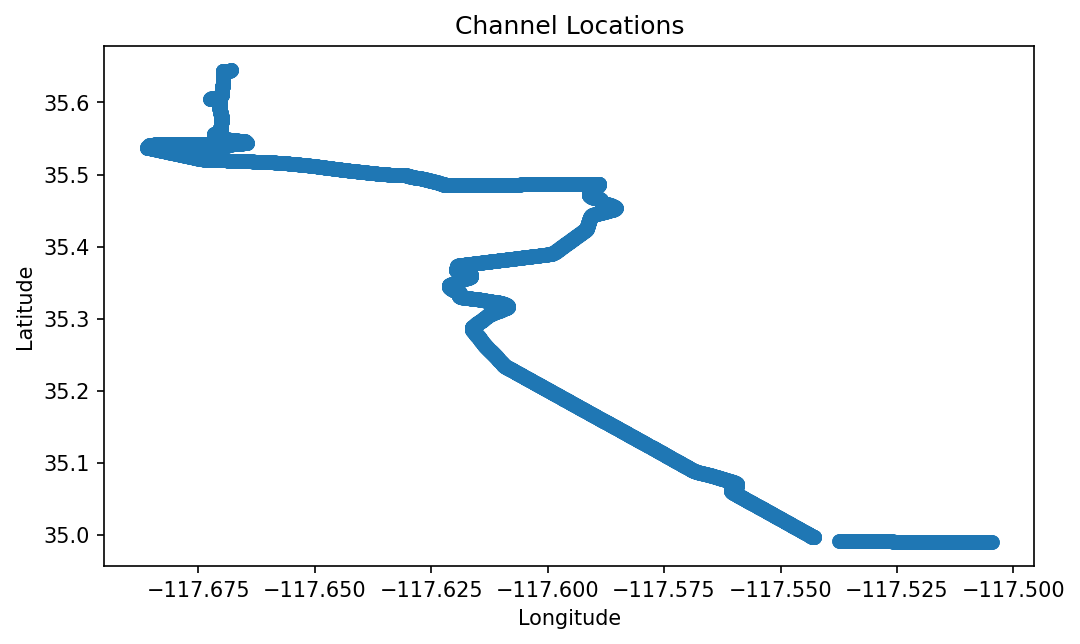

In [4]:
channel_location_file = os.path.join(Info_dir, "Ridgecrest_South-100km.csv")
channel_location_df = pd.read_csv(channel_location_file)
channel_location_df_good = channel_location_df[
    channel_location_df['latitude'].notna() & channel_location_df['longitude'].notna()
]
print(channel_location_df_good.head())

fig = plt.figure(figsize=(16 / 2, 9 / 2), dpi=150)
plt.plot(
    channel_location_df_good['longitude'], channel_location_df_good['latitude'], 'o'
)
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title('Channel Locations')
plt.show()

# Read and Plot continuous data in the `CFR`, `ZFP`, `DS`, and `LF` directories

Reading and plotting data in CFR directory...
Selected one example CFR h5 file: /DASdata/Ridgecrest_South/CFR/2023/11/Ridgecrest_South-20231123T094306Z.h5
Reading data from /DASdata/Ridgecrest_South/CFR/2023/11/Ridgecrest_South-20231123T094306Z.h5 with dataKind = Proc
Data shape: (10000, 179999)
{'dx': 10.209524, 'dt': 0.01, 'fs': 100.0, 'nt': 179999, 'nx': 10000, 'begTime': datetime.datetime(2023, 11, 23, 9, 43, 6, 557000, tzinfo=tzutc()), 'endTime': datetime.datetime(2023, 11, 23, 10, 13, 6, 537000, tzinfo=tzutc()), 'unit': 'strainrate (1e-6/s)'}
Plotting the data from /DASdata/Ridgecrest_South/CFR/2023/11/Ridgecrest_South-20231123T094306Z.h5...


Reading and plotting data in DS directory...
Selected one example DS h5 file: /DASdata/Ridgecrest_South/DS/2023/11/Ridgecrest_South-20231123T094306Z.h5
Reading data from /DASdata/Ridgecrest_South/DS/2023/11/Ridgecrest_South-20231123T094306Z.h5 with dataKind = Proc
Data shape: (2000, 45000)
{'dx': 51.04762077331543, 'dt': 0.04, 'fs': 25.0, '

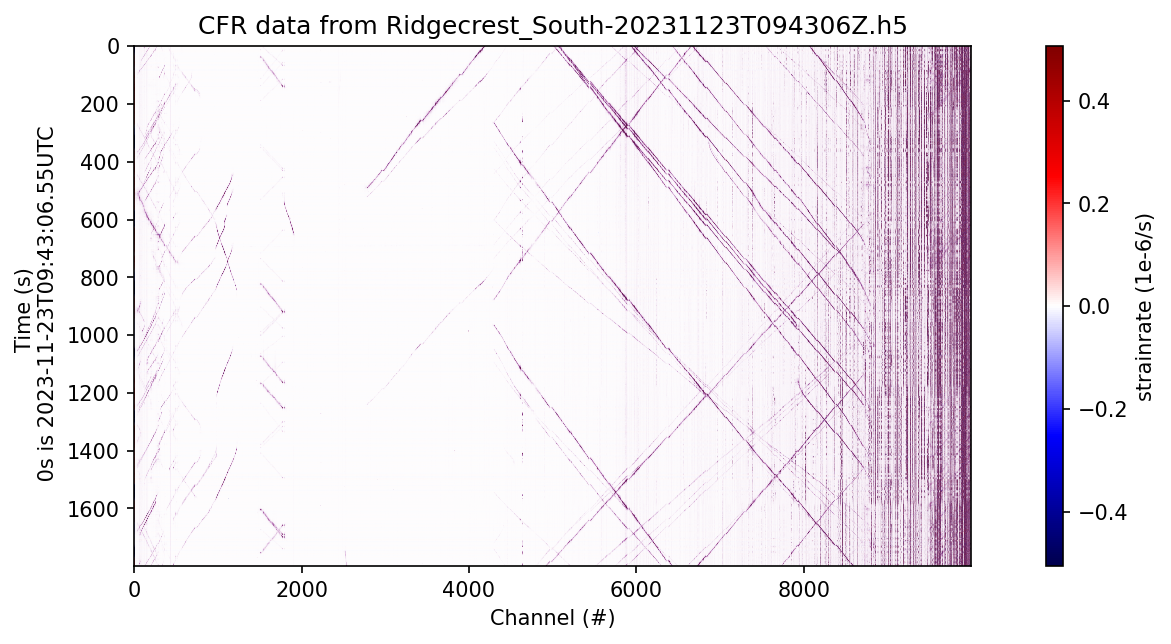

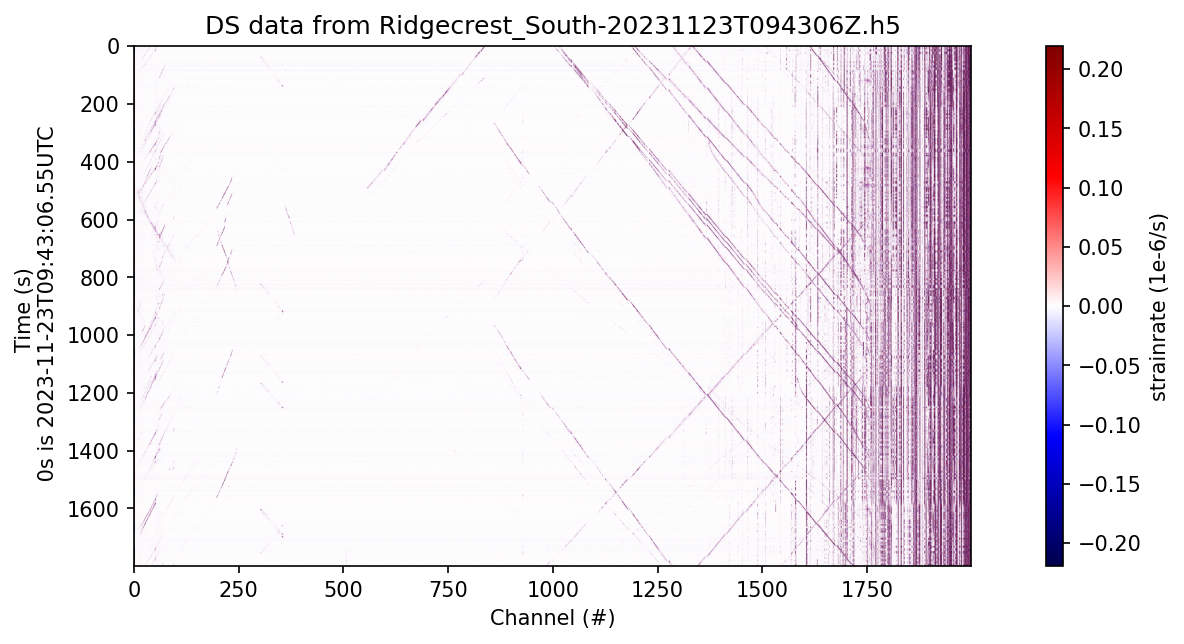

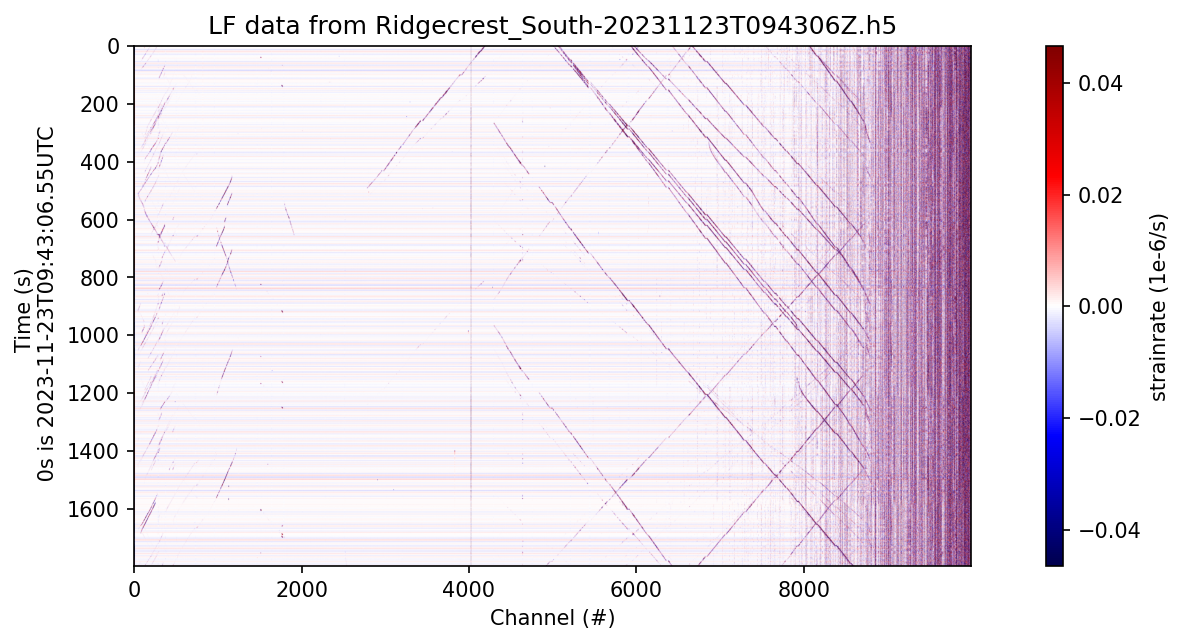

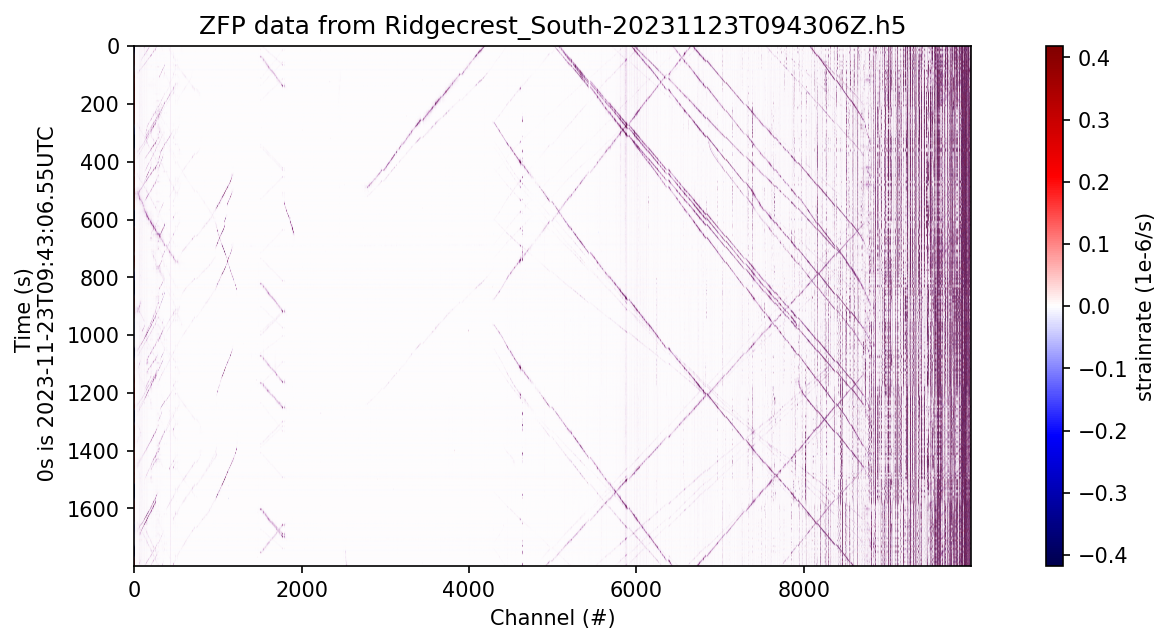

In [5]:
# get the list of h5 files
for dir_tmp in [CFR_dir, DS_dir, LF_dir, ZFP_dir]:
    # for dir_tmp in [LF_dir, ZFP_dir]:
    data_type = os.path.basename(dir_tmp)
    print(f"Reading and plotting data in {data_type} directory...")

    # get the file to be read
    # here we select an example file, you can change it to read other files
    # example_h5_file = f"RidgeCrest-South-2023-12-27T130804Z.h5"
    example_h5_file = f"Ridgecrest_South-20231123T094306Z.h5"

    try:
        h5_file_selected = sorted(
            glob(os.path.join(dir_tmp, f'*/*/{example_h5_file}'))
        )[0]
    except:
        h5_file_selected = sorted(glob(os.path.join(dir_tmp, f'*/*/*.h5')))[0]

    print(f"Selected one example {data_type} h5 file: {h5_file_selected}")

    # load the data from the h5 file
    DAS_data, info = read_continuous_h5_file(h5_file_selected)
    print(f"Data shape: {DAS_data.shape}")
    print(info)
    print(f"Plotting the data from {h5_file_selected}...")

    # preprocess the data

    # # remove the commom mode noise
    # print("Removing common mode noise...")
    # DAS_data = DAS_data - np.median(DAS_data, axis=0, keepdims=True)

    # # remove the linear trend and add tapering window
    # print("Removing linear trend and adding tapering window...")
    # DAS_data = seis_preprocess(DAS_data, alpha=0.10)

    # # bandpass filter the data
    # print("Bandpass filtering the data...")
    # DAS_data = bp_filter(
    #     DAS_data,
    #     fs=info["fs"],
    #     freqmin=2.0,
    #     freqmax=20.0,
    #     preprocess=False,
    # )

    # plot the data
    fig, ax = plt.subplots(figsize=(16 / 2, 9 / 2), dpi=150)
    imshow_das(
        DAS_data,
        info,
        percent=98,
        cmap="seismic",
        fig=fig,
        ax=ax,
        title=f"{data_type} data from {os.path.basename(h5_file_selected)}",
    )
    print(f"\n")

# Reading seismic event information and waveforms in the old format (created before DASHub)

In [6]:
dir_tmp = Events_dir
data_type = os.path.basename(dir_tmp)
print(f"Reading and plotting data in {data_type} directory...")

# get the file to be read
# here we select an example file, you can change it to read other files
event_id = "ci40451695"

Reading and plotting data in Events directory...


In [7]:
catalog_file = os.path.join(dir_tmp, "catalog.csv")
catalog_df = pd.read_csv(catalog_file)
try:
    event_info = catalog_df[catalog_df['event_id'] == event_id].iloc[0]
except:
    raise ValueError(f"Cannot find event {event_id} in catalog {catalog_file}")
print(f"Selected event {event_id} info from catalog:\n{event_info}")

Selected event ci40451695 info from catalog:
event_id                                ci40451695
longitude                              -117.684333
latitude                                 35.922667
depth_km                                      2.09
event_time        2023-12-27T13:19:44.360000+00:00
magnitude                                     2.87
magnitude_type                                  ml
source                                          ci
Name: 72911, dtype: object


Selected one example Events h5 file: /DASdata/Ridgecrest_South/Events/data/ci40451695.h5
Reading /DASdata/Ridgecrest_South/Events/data/ci40451695.h5 in less-info format
Data shape: (10000, 12000)
{'begTime': datetime.datetime(2023, 12, 27, 13, 19, 20, 34000, tzinfo=datetime.timezone.utc), 'endTime': datetime.datetime(2023, 12, 27, 13, 21, 20, 34000, tzinfo=datetime.timezone.utc), 'time': datetime.datetime(2023, 12, 27, 13, 19, 44, 360000, tzinfo=datetime.timezone.utc), 'tbef': 30.0, 'taft': 90.0, 'tref': 5.67, 'dx': 10.209524154663086, 'dt': 0.01, 'nx': 10000, 'nt': 12000, 'time_axis': array([-24.326, -24.316, -24.306, ...,  95.644,  95.654,  95.664]), 'unit': 'strainrate [1e-6/s]'}
Plotting the data from /DASdata/Ridgecrest_South/Events/data/ci40451695.h5...


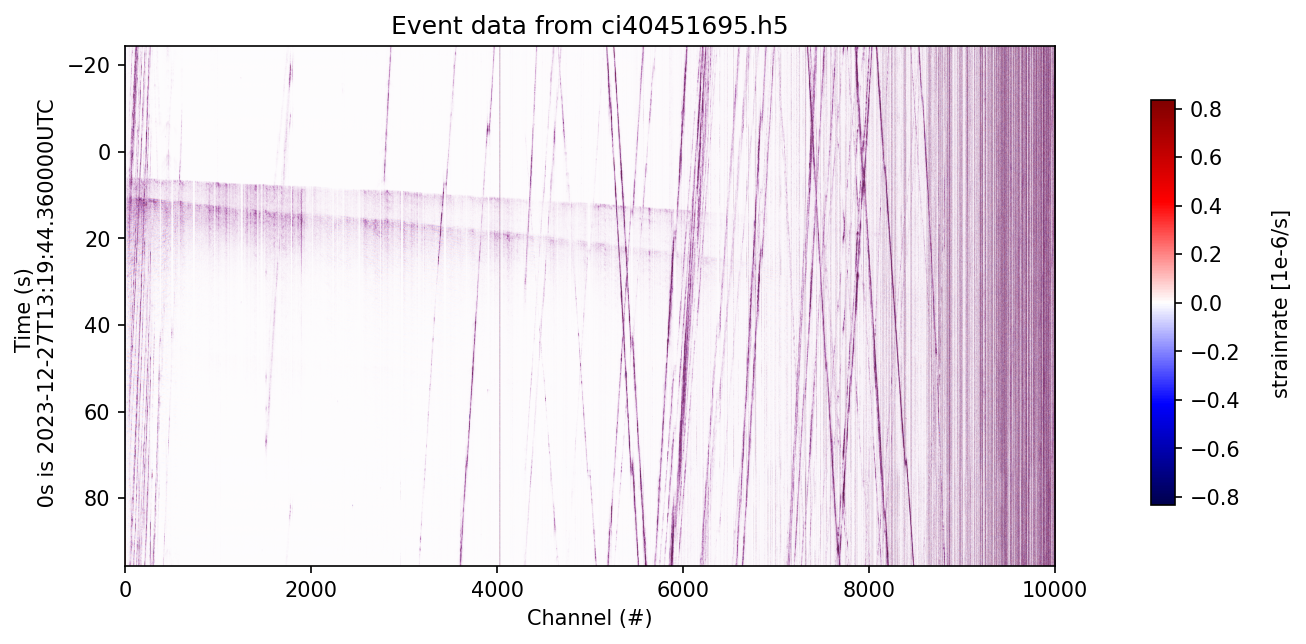

In [8]:
try:
    h5_file_selected = sorted(glob(os.path.join(dir_tmp, f'data/{event_id}.h5')))[0]
except:
    # raise error if the file is not found
    raise FileNotFoundError(f"Cannot find h5 file for event {event_id} in {dir_tmp}")
print(f"Selected one example {data_type} h5 file: {h5_file_selected}")

# load the data from the h5 file
Event_data, info = read_das_event_data_h5_simple(h5_file_selected)
print(f"Data shape: {Event_data.shape}")
print(info)
print(f"Plotting the data from {h5_file_selected}...")

fig, ax = plt.subplots(figsize=(16 / 2, 9 / 2), dpi=150)

vmax = np.nanpercentile(np.abs(Event_data), 98)

ax.imshow(
    Event_data.T,
    extent=[0, info["nx"], info["time_axis"][-1], info["time_axis"][0]],
    aspect='auto',
    cmap='seismic',
    vmax=vmax,
    vmin=-vmax,
)
ax.set_xlabel("Channel (#)")
ax.set_ylabel(
    "Time (s) \n 0s is {}".format(info["time"].isoformat().replace('+00:00', 'UTC'))
)
ax.set_title(f"Event data from {os.path.basename(h5_file_selected)}")

# add colorbar to the right of the last panel out of the subplots, do not change the size of the subplots
cax = fig.add_axes([0.98, 0.2, 0.02, 0.6])  # [left, bottom, width, height]
norm = plt.Normalize(vmin=-vmax, vmax=vmax)
sm = plt.cm.ScalarMappable(cmap='seismic', norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, cax=cax)
cbar.set_label(info["unit"], labelpad=15)

plt.show()

# Reading seismic event information and waveforms in the DASHub format

In [9]:
dir_tmp = "/DASdata/Mammoth_North/Events"
data_type = os.path.basename(dir_tmp)
print(f"Reading and plotting data in {data_type} directory...")

# get the file to be read
# here we select an example file, you can change it to read other files
event_id = "nc75061916"

Reading and plotting data in Events directory...


In [10]:
catalog_file = os.path.join(dir_tmp, "events.csv")
catalog_df = pd.read_csv(catalog_file)
# catalog_df[(catalog_df['distance_km'] <= 50) & (catalog_df['magnitude'] >= 3.0)].sort_values(by='magnitude', ascending=False).head(10)
try:
    event_info = catalog_df[catalog_df['event_id'] == event_id].iloc[0]
except:
    raise ValueError(f"Cannot find event {event_id} in catalog {catalog_file}")
print(f"Selected event {event_id} info from catalog:\n{event_info}")

Selected event nc75061916 info from catalog:
resource_id           quakeml:earthquake.usgs.gov/fdsnws/event/1/que...
event_id                                                     nc75061916
latitude                                                      38.027667
longitude                                                   -118.802167
depth_km                                                           9.53
event_time                             2024-09-14 21:54:04.400000+00:00
magnitude                                                           3.2
magnitude_type                                                       ml
source                                                               nc
version                                                             4.0
distance_km                                                    29.09637
distance_threshold                                           814.453215
time_reference                                                 5.275276
time_before        

Selected one example Events h5 file: /DASdata/Mammoth_North/Events/2024-09/Mammoth_North-nc75061916.h5
Reading /DASdata/Mammoth_North/Events/2024-09/Mammoth_North-nc75061916.h5 in proc format
Data shape: (10000, 12000)
{'begTime': datetime.datetime(2024, 9, 14, 21, 53, 39, 675275, tzinfo=tzutc()), 'endTime': datetime.datetime(2024, 9, 14, 21, 55, 39, 675275, tzinfo=tzutc()), 'time': datetime.datetime(2024, 9, 14, 21, 54, 4, 400000, tzinfo=tzutc()), 'tbef': 30.0, 'taft': 90.0, 'tref': 5.275275559845671, 'dx': 10.209524154663086, 'dt': 0.01, 'nx': 10000, 'nt': 12000, 'time_axis': array([-24.724725, -24.714725, -24.704725, ...,  95.245275,  95.255275,
        95.265275]), 'unit': 'strainrate [1e-6/s]'}
Plotting the data from /DASdata/Mammoth_North/Events/2024-09/Mammoth_North-nc75061916.h5...


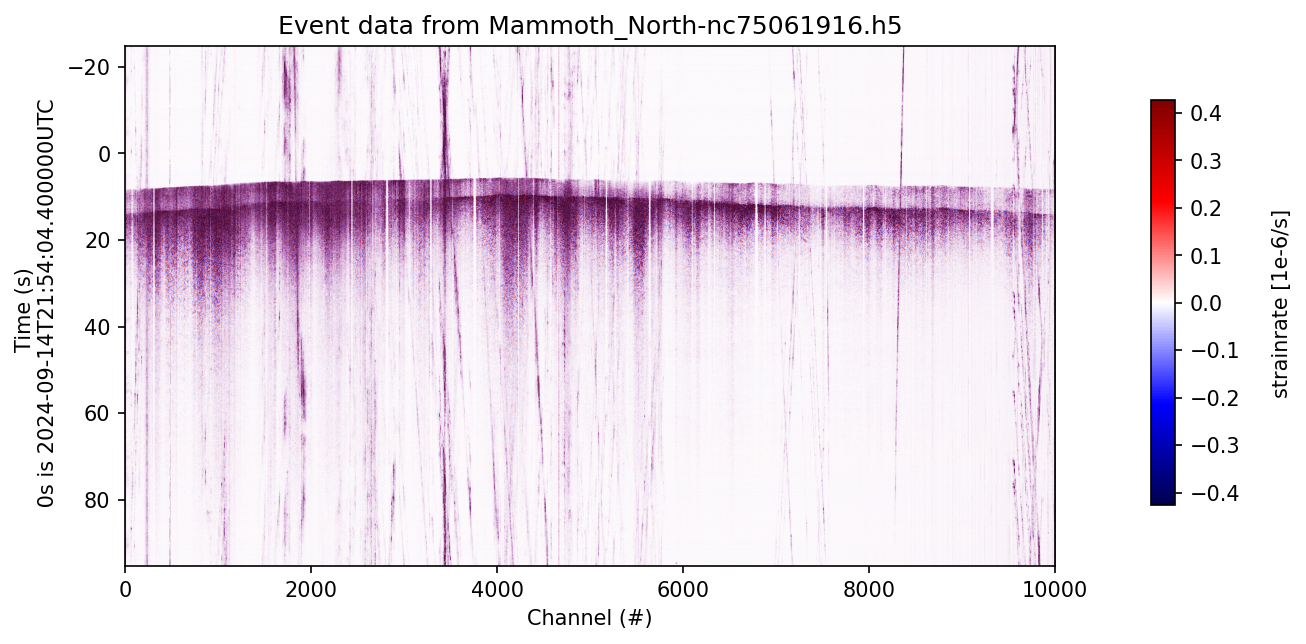

In [11]:
try:
    h5_file_selected = event_info['detail']
except:
    # raise error if the file is not found
    raise FileNotFoundError(f"Cannot find h5 file for event {event_id} in {dir_tmp}")
print(f"Selected one example {data_type} h5 file: {h5_file_selected}")

# load the data from the h5 file
Event_data, info = read_das_event_data_h5_simple(h5_file_selected)
print(f"Data shape: {Event_data.shape}")
print(info)
print(f"Plotting the data from {h5_file_selected}...")

fig, ax = plt.subplots(figsize=(16 / 2, 9 / 2), dpi=150)

vmax = np.nanpercentile(np.abs(Event_data), 98)

ax.imshow(
    Event_data.T,
    extent=[0, info["nx"], info["time_axis"][-1], info["time_axis"][0]],
    aspect='auto',
    cmap='seismic',
    vmax=vmax,
    vmin=-vmax,
)
ax.set_xlabel("Channel (#)")
ax.set_ylabel(
    "Time (s) \n 0s is {}".format(info["time"].isoformat().replace('+00:00', 'UTC'))
)
ax.set_title(f"Event data from {os.path.basename(h5_file_selected)}")

# add colorbar to the right of the last panel out of the subplots, do not change the size of the subplots
cax = fig.add_axes([0.98, 0.2, 0.02, 0.6])  # [left, bottom, width, height]
norm = plt.Normalize(vmin=-vmax, vmax=vmax)
sm = plt.cm.ScalarMappable(cmap='seismic', norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, cax=cax)
cbar.set_label(info["unit"], labelpad=15)

plt.show()